# Deep Variational Models for Collaborative Filtering-Based Recommender Systems

## Project overview

This notebook implements and compares four collaborative-filtering models:

- **DeepMF** — user and item embeddings combined through an inner product.
- **NCF** — user and item embeddings combined through a multilayer perceptron (MLP).
- **VDeepMF** — DeepMF with Gaussian variational latent sampling.
- **VNCF** — NCF with Gaussian variational latent sampling.

The experiments use **FilmTrust** and **MovieLens 1M**. Both datasets are processed automatically in one notebook execution. The model architectures, training approach, and evaluation procedures follow the original implementation style.

The notebook remains an `.ipynb` project. It does not require the user to edit a dataset variable or restart the kernel between datasets.


## Research objective

The project investigates whether adding stochastic variational sampling to user and item latent representations improves rating prediction and recommendation quality.

The comparisons are:

1. DeepMF versus VDeepMF.
2. NCF versus VNCF.

The variational models estimate Gaussian latent parameters and sample vectors through the reparameterization trick. VDeepMF retains the dot-product interaction, while VNCF retains the concatenation and MLP interaction.


## Notebook execution

Run **Kernel → Restart Kernel and Run All** (or the equivalent command in JupyterLab). The notebook will:

1. Set the random seeds and enable deterministic TensorFlow operations when supported.
2. Load FilmTrust and run all four models.
3. Reset the random seeds, load MovieLens 1M, and run all four models.
4. Save the rating-prediction metrics, top-N recommendation metrics, and eight evaluation figures in `results/`.
5. Display combined tables covering both datasets.

No dataset selection or manual code edit is required. The execution order is fixed as FilmTrust (`ft`) followed by MovieLens 1M (`ml1m`). The dataset-specific relevance thresholds and epoch counts are configured in the shared settings section.

**Runtime note:** Training all eight model instances can take substantially longer than running one dataset. Use a TensorFlow-compatible Python environment and a GPU when available.


## Reproducibility and random seeds

The experiment uses `SEED = 42`. The seed is reset at the beginning of each dataset run for Python, NumPy, and TensorFlow/Keras. The 80/20 interaction split also uses `random_state=SEED`. TensorFlow deterministic operations are enabled when the installed TensorFlow version supports them.

A fixed seed improves repeatability but does not guarantee bit-for-bit identical results across different TensorFlow/CUDA versions, devices, or hardware. For the closest reproduction, use the same package versions and execution device. Python's `PYTHONHASHSEED` is a process-start setting and cannot be reliably changed after a Jupyter kernel has already started; this notebook does not claim to control it retroactively.


## Shared configuration

The latent dimension is 5, the batch size for the variational models is 32, and `steps_per_epoch = None` lets Keras infer the number of batches. Dataset-specific settings are retained below.

| Dataset | Relevance threshold | DeepMF epochs | NCF epochs | VDeepMF epochs | VNCF epochs |
|---|---:|---:|---:|---:|---:|
| FilmTrust | 3 | 15 | 8 | 10 | 6 |
| MovieLens 1M | 4 | 10 | 10 | 6 | 9 |


## Dataset description and preprocessing

Each input CSV contains one row per observed user-item rating and the columns `user`, `item`, and `rating`. User and item identifiers are zero-based indices. The notebook derives embedding-table sizes from the maximum identifiers, constructs the user-item input pairs, and uses the rating as the prediction target.

The interaction records are divided into 80% training and 20% held-out data. The same held-out partition is supplied as Keras `validation_data` and later used for reported evaluation. It is therefore a shared validation/evaluation holdout, not a separate validation set plus a separate final test set.

| Dataset | Users | Items | Ratings in the supplied CSV | Rating range | Sparsity |
|---|---:|---:|---:|---:|---:|
| FilmTrust | 1,508 | 2,071 | 35,494 | 0.5–4.0 | 98.86% |
| MovieLens 1M | 6,040 | 3,706 | 1,000,209 | 1.0–5.0 | 95.53% |

Sparsity is calculated as `1 - (observed ratings / (users × items))`.

The FilmTrust file is provided at `datasets/ft.csv` with attribution to its published dataset source. The MovieLens 1M data must be obtained from the official GroupLens distribution and converted to the notebook's three-column format using `datasets/prepare_movielens.py`. The MovieLens data are not bundled here because GroupLens generally does not permit public redistribution without separate permission. See `datasets/README.md` for the source and preparation instructions.


## Model architectures

### DeepMF

DeepMF maps each user and item identifier to a latent embedding vector and computes their inner product to predict a rating.

### NCF

NCF concatenates user and item embeddings and passes the combined representation through the original multilayer perceptron with ReLU activations and dropout.

### VDeepMF

VDeepMF transforms user and item embeddings into Gaussian mean and log-variance parameters, samples latent vectors using the reparameterization trick, and computes their inner product.

### VNCF

VNCF uses the same variational sampling operation as VDeepMF, then concatenates the sampled user and item vectors and passes them through the nonlinear interaction layers.

The model-building statements below retain the original layer arrangements, latent dimension, activation functions, dropout values, optimizer, and regression loss.


## Training and evaluation protocol

All four models are trained on the same training interactions and use the same held-out partition. The optimizer is Adam and the loss is mean squared error; mean absolute error is also tracked during training. VDeepMF and VNCF use ten stochastic forward passes at inference, and the predictions are averaged row by row.

Rating-prediction metrics:

- **MAE:** average absolute prediction error; lower is better.
- **MSE:** average squared prediction error; lower is better.
- **R²:** variance explained relative to a mean-prediction baseline; higher is better.

Top-N recommendation metrics:

- **Precision and Recall:** calculated using the dataset-specific relevance threshold.
- **F1:** harmonic mean of Precision and Recall.
- **Novelty:** estimated from item frequencies in the held-out partition.
- **nDCG:** calculated with scikit-learn's `ndcg_score` using observed ratings as relevance values.

The recommendation candidates are the held-out interactions for each user, not every unseen item in the complete catalog.


## Imports and shared utilities

The following cell imports the original numerical, plotting, deep-learning, and evaluation libraries. The model code continues to use the Keras functional API, with TensorFlow providing the backend and device selection.


In [1]:
import os
import math
import random
import gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Embedding, Flatten, Input, Dropout, Dense, Concatenate, Dot, Lambda
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import precision_score, recall_score, ndcg_score, mean_absolute_error, mean_squared_error, r2_score

os.makedirs('./results', exist_ok=True)


## Fixed-seed configuration

The seed is applied once before the batch workflow and reset again at the start of each dataset. Resetting before each dataset makes the runs independent of random-number state left by the preceding dataset. Deterministic TensorFlow operations are enabled when supported by the installed version.


In [2]:
SEED = 42

# Enable deterministic TensorFlow operations when the installed version supports them.
try:
    tf.config.experimental.enable_op_determinism()
    print('Deterministic TensorFlow operations are enabled.')
except (AttributeError, RuntimeError) as error:
    print('TensorFlow deterministic operations could not be enabled:', error)


def set_random_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


DATASETS = ['ft', 'ml1m']
DATASET_CONFIG = {
    'ft': {
        'like_threshold': 3,
        'deepmf_epochs': 15,
        'ncf_epochs': 8,
        'vdeepmf_epochs': 10,
        'vncf_epochs': 6
    },
    'ml1m': {
        'like_threshold': 4,
        'deepmf_epochs': 10,
        'ncf_epochs': 10,
        'vdeepmf_epochs': 6,
        'vncf_epochs': 9
    }
}

latent_dim = 5
steps_per_epoch = None
batch_size = 32
device = '/GPU:0' if tf.config.list_physical_devices('GPU') else '/CPU:0'

print('Execution device:', device)
print('Dataset execution order:', DATASETS)


Deterministic TensorFlow operations are enabled.
Execution device: /CPU:0
Dataset execution order: ['ft', 'ml1m']


## Per-dataset model training and evaluation

`run_experiment(dataset)` contains the data loading, train/test split, model construction, model fitting, prediction, ranking, and plotting workflow. It returns the rating and recommendation metrics for the selected dataset. The model definitions follow the functional Keras style used throughout this notebook.

The function is called automatically for both dataset aliases in the next cell.


In [3]:
def run_experiment(dataset):
    """Train and evaluate all four models on one dataset."""
    tf.keras.backend.clear_session()
    set_random_seed(SEED)
    gc.collect()

    dataset_config = DATASET_CONFIG[dataset]
    like_threshold = dataset_config['like_threshold']
    deepmf_epochs = dataset_config['deepmf_epochs']
    ncf_epochs = dataset_config['ncf_epochs']
    vdeepmf_epochs = dataset_config['vdeepmf_epochs']
    vncf_epochs = dataset_config['vncf_epochs']

    print('\n' + '=' * 72)
    print('Running dataset:', dataset)
    print('Relevance threshold:', like_threshold)
    print('Training epochs:', deepmf_epochs, ncf_epochs, vdeepmf_epochs, vncf_epochs)
    print('=' * 72)
    os.makedirs('./results', exist_ok=True)

    df = pd.read_csv('./datasets/' + dataset + '.csv', delimiter = ',')

    num_users = df.user.max() + 1
    num_items = df.item.max() + 1

    X = df[['user', 'item']].to_numpy()
    y = df[['rating']].to_numpy()

    from sklearn.model_selection import train_test_split

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)

    X_train = [X_train[:,0], X_train[:,1]]
    X_test = [X_test[:,0], X_test[:,1]]

    user_input = Input(shape=[1])
    user_embedding = Embedding(num_users, latent_dim)(user_input)
    user_vec = Flatten()(user_embedding)

    item_input = Input(shape=[1])
    item_embedding = Embedding(num_items, latent_dim)(item_input)
    item_vec = Flatten()(item_embedding)

    dot = Dot(axes=1)([item_vec, user_vec])

    DeepMF = Model([user_input, item_input], dot)

    with tf.device(device):
        DeepMF.compile(optimizer='adam', metrics=['mae'], loss='mean_squared_error')
        DeepMF.summary()

        deepmf_report = DeepMF.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=deepmf_epochs, steps_per_epoch=steps_per_epoch, verbose=1)

    item_input = Input(shape=[1], name='item-input')
    item_embedding = Embedding(num_items, latent_dim, name='item-embedding')(item_input)
    item_vec = Flatten(name='item-flatten')(item_embedding)

    user_input = Input(shape=[1], name='user-input')
    user_embedding = Embedding(num_users, latent_dim, name='user-embedding')(user_input)
    user_vec = Flatten(name='user-flatten')(user_embedding)

    concat = Concatenate(axis=1, name='item-user-concat')([item_vec, user_vec])
    fc_1 = Dense(70, name='fc-1', activation='relu')(concat)
    fc_1_dropout = Dropout(0.5, name='fc-1-dropout')(fc_1)
    fc_2 = Dense(30, name='fc-2', activation='relu')(fc_1_dropout)
    fc_2_dropout = Dropout(0.4, name='fc-2-dropout')(fc_2)
    fc_3 = Dense(1, name='fc-3', activation='relu')(fc_2_dropout)

    NCF = Model([user_input, item_input], fc_3)

    with tf.device(device):
        NCF.compile(optimizer='adam', metrics=['mae'], loss='mean_squared_error')
        NCF.summary()

        ncf_report = NCF.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=ncf_epochs, steps_per_epoch=steps_per_epoch, verbose=1)

    # Shared reparameterization sampling function
    def sampling(args):
        z_mean, z_log_var = args
        epsilon = tf.random.normal(shape=tf.shape(z_mean), mean=0., stddev=1)
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

    # User branch
    user_input = Input(shape=[1])
    user_embedding = Embedding(num_users, latent_dim)(user_input)
    user_embedding_mean = Dense(latent_dim)(user_embedding)
    user_embedding_var = Dense(latent_dim)(user_embedding)  # Log-variance parameters
    user_embedding_z = Lambda(sampling)([user_embedding_mean, user_embedding_var])
    user_vec = Flatten()(user_embedding_z)

    # Item branch
    item_input = Input(shape=[1])
    item_embedding = Embedding(num_items, latent_dim)(item_input)
    item_embedding_mean = Dense(latent_dim)(item_embedding)
    item_embedding_var = Dense(latent_dim)(item_embedding)  # Log-variance parameters
    item_embedding_z = Lambda(sampling)([item_embedding_mean, item_embedding_var])
    item_vec = Flatten()(item_embedding_z)

    # Dot product
    dot = Dot(axes=1)([user_vec, item_vec])

    # Model
    VDeepMF = Model([user_input, item_input], dot)

    with tf.device(device):
        VDeepMF.compile(optimizer='adam', metrics=['mae'], loss='mean_squared_error')
        VDeepMF.summary()

        vdeepmf_report = VDeepMF.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=vdeepmf_epochs, batch_size=batch_size, steps_per_epoch=steps_per_epoch, verbose=1)

    # User branch
    user_input = Input(shape=[1])
    user_embedding = Embedding(num_users, latent_dim)(user_input)
    user_embedding_mean = Dense(latent_dim)(user_embedding)
    user_embedding_var = Dense(latent_dim)(user_embedding)  # Log-variance parameters
    user_embedding_z = Lambda(sampling)([user_embedding_mean, user_embedding_var])
    user_vec = Flatten()(user_embedding_z)

    # Item branch
    item_input = Input(shape=[1])
    item_embedding = Embedding(num_items + 1, latent_dim)(item_input)
    item_embedding_mean = Dense(latent_dim)(item_embedding)
    item_embedding_var = Dense(latent_dim)(item_embedding)  # Log-variance parameters
    item_embedding_z = Lambda(sampling)([item_embedding_mean, item_embedding_var])
    item_vec = Flatten()(item_embedding_z)

    # Concatenate user & item embeddings
    concat = Concatenate(axis=1)([user_vec, item_vec])

    # Fully connected layers
    fc_1 = Dense(80, activation='relu', name='fc-1')(concat)
    fc_1_dropout = Dropout(0.6, name='fc-1-dropout')(fc_1)
    fc_2 = Dense(25, activation='relu', name='fc-2')(fc_1_dropout)
    fc_2_dropout = Dropout(0.4, name='fc-2-dropout')(fc_2)
    fc_3 = Dense(1, activation='relu', name='fc-3')(fc_2_dropout)

    # Model
    VNCF = Model([user_input, item_input], fc_3)

    with tf.device(device):
        VNCF.compile(optimizer='adam', metrics=['mae'], loss='mean_squared_error')
        VNCF.summary()

        vncf_report = VNCF.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=vncf_epochs, batch_size=batch_size, steps_per_epoch=steps_per_epoch, verbose=1)

    methods = ['vdeepmf', 'deepmf', 'vncf', 'ncf']

    preds = pd.DataFrame()

    preds['user'] = X_test[0]
    preds['item'] = X_test[1]

    preds['y_test'] = y_test

    y_true = preds['y_test'].to_numpy()

    preds['deepmf'] = DeepMF.predict(X_test)

    preds['ncf'] = NCF.predict(X_test)

    n_repeats = 10

    predictions = None

    for i in range(n_repeats):
        if i == 0:
            predictions = VDeepMF.predict(X_test)
        else:
            predictions = np.append(predictions, VDeepMF.predict(X_test), axis=1)

    preds['vdeepmf'] = np.mean(predictions, axis=1)

    predictions = None

    for i in range(n_repeats):
        if i == 0:
            predictions = VNCF.predict(X_test)
        else:
            predictions = np.append(predictions, VNCF.predict(X_test), axis=1)

    preds['vncf'] = np.mean(predictions, axis=1)

    print('MAE:')
    for m in methods:
        print('-', m, ':', mean_absolute_error(preds['y_test'], preds[m]))

    print('MSE:')
    for m in methods:
        print('-', m, ':', mean_squared_error(preds['y_test'], preds[m]))

    print('R2:')
    for m in methods:
        print('-', m, ':', r2_score(preds['y_test'], preds[m]))

    rating_metrics = pd.DataFrame([
        {
            'dataset': dataset,
            'model': m,
            'MAE': mean_absolute_error(preds['y_test'], preds[m]),
            'MSE': mean_squared_error(preds['y_test'], preds[m]),
            'R2': r2_score(preds['y_test'], preds[m])
        }
        for m in methods
    ])

    rating_metrics.to_csv('./results/' + dataset + '-rating-metrics.csv', index=False)
    print('\nRating-prediction summary:')
    display(rating_metrics)

    recommendations = {}

    for m in methods:
        recommendations[m] = {}

    X = preds[['user', 'item']].to_numpy()
    for user_id in np.unique(X[:,0]):
        indices = np.where(X[:,0] == user_id)[0]

        for m in methods:
            user_pred = np.array([preds[m].to_numpy()[i] for i in indices])
            user_rec = [indices[pos] for pos in np.argsort(user_pred)[::-1]]
            recommendations[m][user_id] = user_rec

    num_recommendations = [2,3,4,5,6,7,8,9,10]

    def recommender_precision_recall(recommendations, y_true, y_pred, N, threshold):
        precision = 0
        recall = 0
        count = 0

        for user_id, indices in recommendations.items():

            valid_user = False
            rec_true = np.zeros(len(indices))
            rec_pred = np.zeros(len(indices))

            for i, index in enumerate(indices):

                if y_true[index] >= threshold:
                    rec_true[i] = 1
                    valid_user = True

                if i < N and y_pred[index] >= threshold:
                    rec_pred[i] = 1

            if valid_user:
                precision += precision_score(rec_true, rec_pred, zero_division=0)
                recall += recall_score(rec_true, rec_pred)
                count += 1

        if count == 0:
            return 0, 0

        return precision/count, recall/count

    precision = {}
    recall = {}
    f1 = {}

    for m in methods:
        print(m)

        precision[m] = np.zeros(len(num_recommendations))
        recall[m] = np.zeros(len(num_recommendations))

        for i, n in enumerate(num_recommendations):
            y_pred = preds[m].to_numpy()
            precision[m][i], recall[m][i] = recommender_precision_recall(recommendations[m], y_true, y_pred, n, like_threshold)

        f1[m] = np.divide(2 * precision[m] * recall[m], precision[m] + recall[m], out=np.zeros_like(precision[m]), where=(precision[m] + recall[m]) != 0)

    for m in methods:
        c = 'blue' if 'deepmf' in m else 'red'
        alpha = 1 if m[0] == 'v' else 0.6
        ls = '-' if m[0] == 'v' else '--'

        plt.plot(recall[m], precision[m], c=c, ls=ls, alpha=alpha, label=m)

        if m == 'vdeepmf':
            for i,(r,p) in enumerate(zip(recall[m], precision[m])):
                plt.annotate(num_recommendations[i], (r,p), textcoords="offset points", xytext=(5,5), ha='center')

    plt.xlabel('Recall', fontsize=15);
    plt.ylabel('Precision', fontsize=15)

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(bbox_to_anchor=(0,1.02,1,0.2), fontsize=12, loc="lower left", mode="expand", borderaxespad=0, ncol=len(methods), handlelength=1.2)

    plt.grid(True)

    ylim_min, ylim_max = plt.ylim()
    plt.ylim((ylim_min, ylim_max * 1.02))

    plt.savefig('./results/' + dataset + '-precision-recall.png', dpi=300)

    plt.show()
    plt.close()

    for m in methods:
        c = 'blue' if 'deepmf' in m else 'red'
        alpha = 1 if m[0] == 'v' else 0.6
        ls = '-' if m[0] == 'v' else '--'

        plt.plot(num_recommendations, f1[m], c=c, ls=ls, alpha=alpha, label=m)

    plt.xlabel('Number of recommendations', fontsize=15);
    plt.ylabel('F1', fontsize=15)

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(bbox_to_anchor=(0,1.02,1,0.2), fontsize=12, loc="lower left", mode="expand", borderaxespad=0, ncol=len(methods), handlelength=1.2)

    plt.grid(True)

    ylim_min, ylim_max = plt.ylim()
    plt.ylim((ylim_min, ylim_max * 1.02))

    plt.savefig('./results/' + dataset + '-f1.png', dpi=300)

    plt.show()
    plt.close()

    def recommender_novelty(recommendations, y_true, y_pred, num_recommendations):
        novelty = np.zeros(len(num_recommendations))
        count = np.zeros(len(num_recommendations))

        bincount = np.bincount(X_test[1])

        for user_id, indices in recommendations.items():
            for i, n in enumerate(num_recommendations):
                for index in indices[:n]:
                    item_id = X_test[1][index]
                    num_item_ratings = bincount[item_id]
                    total_num_ratings = len(X_test[1])
                    pi = num_item_ratings / total_num_ratings
                    novelty[i] += -math.log(pi,2)
                    count[i] += 1

        return novelty/count

    novelty_results = {}

    for m in methods:
        print(m)

        y_pred = preds[m].to_numpy()
        novelty = recommender_novelty(recommendations[m], y_true, y_pred, num_recommendations)
        novelty_results[m] = novelty.copy()

        c = 'blue' if 'deepmf' in m else 'red'
        alpha = 1 if m[0] == 'v' else 0.6
        ls = '-' if m[0] == 'v' else '--'

        plt.plot(num_recommendations, novelty, c=c, ls=ls, alpha=alpha, label=m)

    plt.xlabel('Number of recommendations', fontsize=15);
    plt.ylabel('Novelty', fontsize=15)

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(bbox_to_anchor=(0,1.02,1,0.2), fontsize=12, loc="lower left", mode="expand", borderaxespad=0, ncol=len(methods), handlelength=1.2)

    plt.grid(True)

    ylim_min, ylim_max = plt.ylim()
    plt.ylim((ylim_min, ylim_max * 1.02))

    plt.savefig('./results/' + dataset + '-novelty.png', dpi=300)

    plt.show()
    plt.close()

    def recommender_ndcg(recommendations, y_true, y_pred, N):
        ndcg = 0
        count = 0

        for indices in recommendations.values():
            if len(indices) > 1:
                user_true = np.array([y_true[i] for i in indices])
                user_pred = np.array([y_pred[i] for i in indices])

                user_true = np.expand_dims(user_true, axis=0)
                user_pred = np.expand_dims(user_pred, axis=0)

                ndcg += ndcg_score(user_true, user_pred, k=N, ignore_ties=False)
                count += 1

        if count == 0:
            return 0

        return ndcg / count

    ndcg_results = {}

    for m in methods:
        print(m)

        ndcg = np.zeros(len(num_recommendations))

        for i, n in enumerate(num_recommendations):
            y_pred = preds[m].to_numpy()
            ndcg[i] = recommender_ndcg(recommendations[m], y_true, y_pred, n)

        ndcg_results[m] = ndcg.copy()

        c = 'blue' if 'deepmf' in m else 'red'
        alpha = 1 if m[0] == 'v' else 0.6
        ls = '-' if m[0] == 'v' else '--'

        plt.plot(num_recommendations, ndcg, c=c, ls=ls, alpha=alpha, label=m)

    plt.xlabel('Number of recommendations', fontsize=15);
    plt.ylabel('NDCG', fontsize=15)

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(bbox_to_anchor=(0,1.02,1,0.2), fontsize=12, loc="lower left", mode="expand", borderaxespad=0, ncol=len(methods), handlelength=1.2)

    plt.grid(True)

    plt.savefig('./results/' + dataset + '-ndcg.png', dpi=300)

    plt.show()
    plt.close()



    ranking_rows = []
    for m in methods:
        for i, n in enumerate(num_recommendations):
            ranking_rows.append({
                'dataset': dataset,
                'model': m,
                'N': n,
                'Precision': precision[m][i],
                'Recall': recall[m][i],
                'F1': f1[m][i],
                'Novelty': novelty_results[m][i],
                'nDCG': ndcg_results[m][i]
            })

    ranking_metrics = pd.DataFrame(ranking_rows)
    ranking_metrics.to_csv('./results/' + dataset + '-ranking-metrics.csv', index=False)
    print('\nTop-N recommendation summary:')
    display(ranking_metrics)

    return {
        'dataset': dataset,
        'rating_metrics': rating_metrics,
        'ranking_metrics': ranking_metrics
    }

## Run both datasets and collect the results

Run this cell once after defining `run_experiment`. It processes FilmTrust and MovieLens 1M in the configured order, then writes combined CSV tables for direct comparison.




Running dataset: ft
Relevance threshold: 3
Training epochs: 15 8 10 6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 5)      │     10,355 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 5)      │      7,540 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 5)         │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 5)         │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1)         │          0 │ flatten_1[0][0],  │
│                     │                   │            │ flatten[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,895 (69.90 KB)

 Trainable params: 17,895 (69.90 KB)

 Non-trainable params: 0 (0.00 B)

... (17 outputs left out)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
888/888 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 1.9464 - mae: 1.1355 - val_loss: 0.9478 - val_mae: 0.8096
Epoch 2/6
888/888 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.2142 - mae: 0.8923 - val_loss: 0.8650 - val_mae: 0.7565
Epoch 3/6
888/888 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.0388 - mae: 0.8223 - val_loss: 0.8347 - val_mae: 0.7293
Epoch 4/6
888/888 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.9194 - mae: 0.7706 - val_loss: 0.7498 - val_mae: 0.6922
Epoch 5/6
888/888 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.8102 - mae: 0.7194 - val_loss: 0.7095 - val_mae: 0.6620
Epoch 6/6
888/888 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7408 - mae: 0.6848 - val_loss: 0.7036 - val_mae: 0.6582
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 878us/step
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 882us/step
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 878us/step
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 902us/step
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 883us/step
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step

,dataset,model,MAE,MSE,R2
0,ft,vdeepmf,0.636879,0.696933,0.185261
1,ft,deepmf,0.798979,1.216966,-0.422677
2,ft,vncf,0.653174,0.693856,0.188858
3,ft,ncf,0.626976,0.678468,0.206847


vdeepmf
deepmf
vncf
ncf


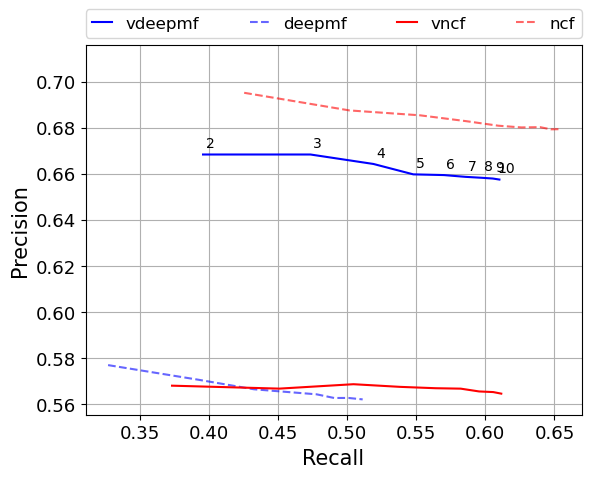

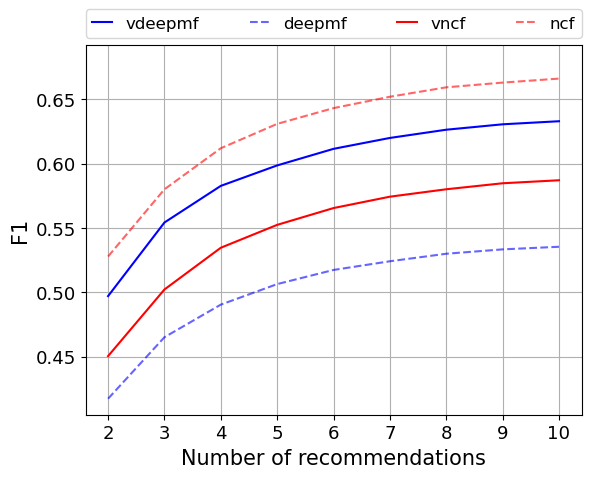

vdeepmf
deepmf
vncf
ncf


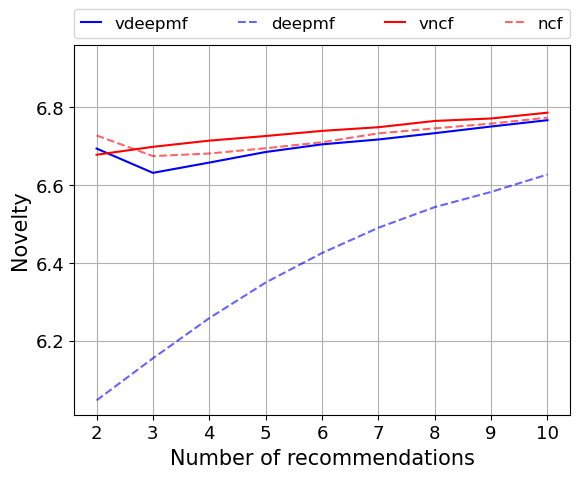

vdeepmf
deepmf
vncf
ncf


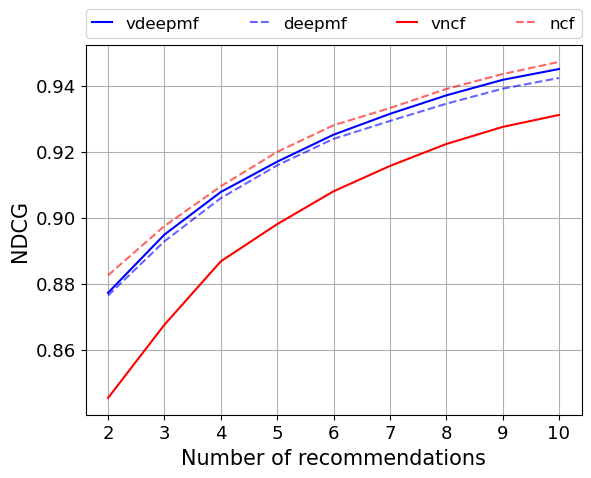


Top-N recommendation summary:


,dataset,model,N,Precision,Recall,F1,Novelty,nDCG
0,ft,vdeepmf,2,0.668367,0.395770,0.497153,6.693490,0.877305
1,ft,vdeepmf,3,0.668367,0.473514,0.554315,6.631160,0.894935
2,ft,vdeepmf,4,0.664257,0.519085,0.582766,6.657544,0.907844
3,ft,vdeepmf,5,0.659751,0.547916,0.598655,6.684676,0.917028
4,ft,vdeepmf,6,0.659439,0.570107,0.611528,6.704320,0.925207
5,ft,vdeepmf,7,0.658669,0.585615,0.619998,6.716805,0.931518
6,ft,vdeepmf,8,0.658259,0.597462,0.626389,6.732985,0.937116
7,ft,vdeepmf,9,0.657941,0.605424,0.630590,6.750087,0.941830
8,ft,vdeepmf,10,0.657496,0.610221,0.632977,6.766292,0.945101
9,ft,deepmf,2,0.576956,0.327053,0.417463,6.047362,0.876465



Running dataset: ml1m
Relevance threshold: 4
Training epochs: 10 10 6 9


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 5)      │     18,530 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 5)      │     30,200 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 5)         │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 5)         │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1)         │          0 │ flatten_1[0][0],  │
│                     │                   │            │ flatten[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 48,730 (190.35 KB)

... (19 outputs left out)

 Non-trainable params: 0 (0.00 B)

Epoch 1/9
25006/25006 ━━━━━━━━━━━━━━━━━━━━ 39s 1ms/step - loss: 1.1066 - mae: 0.8317 - val_loss: 0.8462 - val_mae: 0.7249
Epoch 2/9
25006/25006 ━━━━━━━━━━━━━━━━━━━━ 37s 1ms/step - loss: 0.8753 - mae: 0.7395 - val_loss: 0.8319 - val_mae: 0.7206
Epoch 3/9
25006/25006 ━━━━━━━━━━━━━━━━━━━━ 37s 1ms/step - loss: 0.8543 - mae: 0.7294 - val_loss: 0.8166 - val_mae: 0.7101
Epoch 4/9
25006/25006 ━━━━━━━━━━━━━━━━━━━━ 38s 2ms/step - loss: 0.8417 - mae: 0.7233 - val_loss: 0.8107 - val_mae: 0.7088
Epoch 5/9
25006/25006 ━━━━━━━━━━━━━━━━━━━━ 37s 1ms/step - loss: 0.8316 - mae: 0.7180 - val_loss: 0.8014 - val_mae: 0.7039
Epoch 6/9
25006/25006 ━━━━━━━━━━━━━━━━━━━━ 38s 2ms/step - loss: 0.8243 - mae: 0.7147 - val_loss: 0.7981 - val_mae: 0.7049
Epoch 7/9
25006/25006 ━━━━━━━━━━━━━━━━━━━━ 37s 1ms/step - loss: 0.8156 - mae: 0.7107 - val_loss: 0.7896 - val_mae: 0.6996
Epoch 8/9
25006/25006 ━━━━━━━━━━━━━━━━━━━━ 37s 1ms/step - loss: 0.8090 - mae: 0.7074 - val_loss: 0.7864 - val_mae: 0.6951
Epoch 9/9
25006/25006 ━━

,dataset,model,MAE,MSE,R2
0,ml1m,vdeepmf,0.684081,0.760223,0.392178
1,ml1m,deepmf,0.702945,0.802133,0.358669
2,ml1m,vncf,0.698247,0.787264,0.370557
3,ml1m,ncf,0.699672,0.789808,0.368523


vdeepmf
deepmf
vncf
ncf


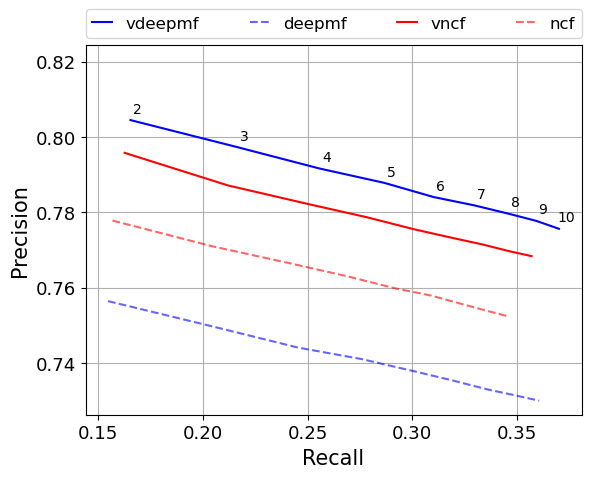

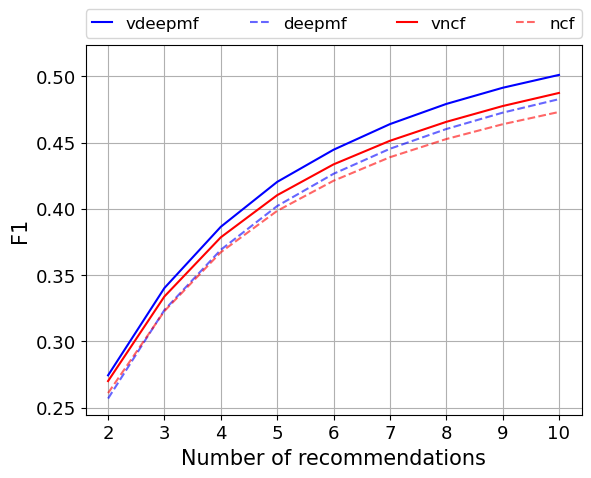

vdeepmf
deepmf
vncf
ncf


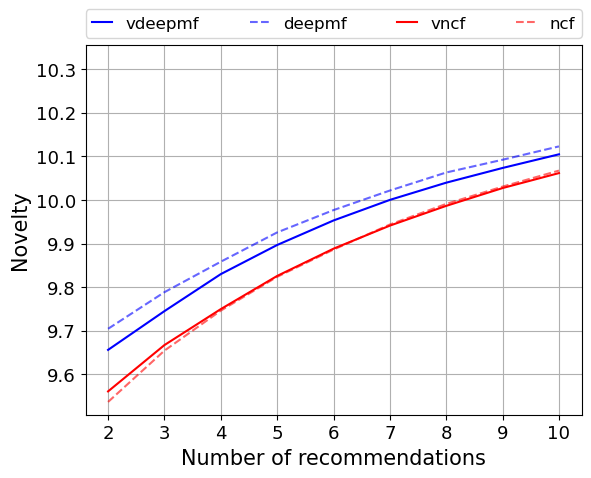

vdeepmf
deepmf
vncf
ncf


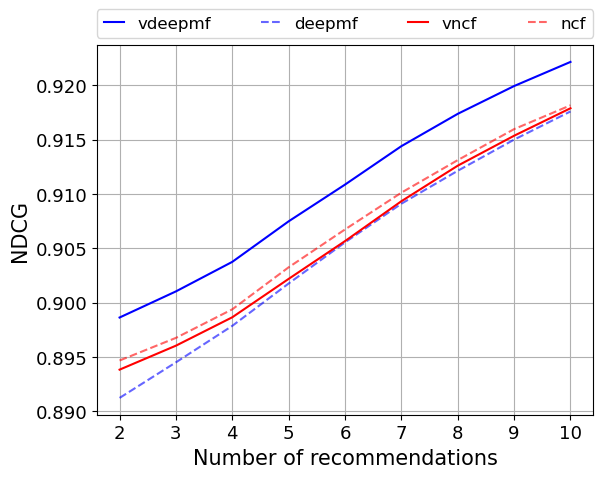


Top-N recommendation summary:


,dataset,model,N,Precision,Recall,F1,Novelty,nDCG
0,ml1m,vdeepmf,2,0.804493,0.165412,0.274403,9.655970,0.898644
1,ml1m,vdeepmf,3,0.797339,0.216318,0.340311,9.744900,0.901049
2,ml1m,vdeepmf,4,0.791660,0.255643,0.386483,9.829838,0.903768
3,ml1m,vdeepmf,5,0.787843,0.286646,0.420353,9.896656,0.907499
4,ml1m,vdeepmf,6,0.784074,0.310281,0.444615,9.952931,0.910879
5,ml1m,vdeepmf,7,0.781851,0.329830,0.463943,10.000140,0.914417
6,ml1m,vdeepmf,8,0.779682,0.345866,0.479172,10.039652,0.917392
7,ml1m,vdeepmf,9,0.777775,0.359125,0.491368,10.073409,0.919951
8,ml1m,vdeepmf,10,0.775662,0.370080,0.501084,10.104746,0.922170
9,ml1m,deepmf,2,0.756472,0.154711,0.256885,9.704353,0.891243



COMBINED RATING-PREDICTION RESULTS


,dataset,model,MAE,MSE,R2
0,ft,vdeepmf,0.636879,0.696933,0.185261
1,ft,deepmf,0.798979,1.216966,-0.422677
2,ft,vncf,0.653174,0.693856,0.188858
3,ft,ncf,0.626976,0.678468,0.206847
4,ml1m,vdeepmf,0.684081,0.760223,0.392178
5,ml1m,deepmf,0.702945,0.802133,0.358669
6,ml1m,vncf,0.698247,0.787264,0.370557
7,ml1m,ncf,0.699672,0.789808,0.368523



COMBINED TOP-N RECOMMENDATION RESULTS


,dataset,model,N,Precision,Recall,F1,Novelty,nDCG
0,ft,vdeepmf,2,0.668367,0.395770,0.497153,6.693490,0.877305
1,ft,vdeepmf,3,0.668367,0.473514,0.554315,6.631160,0.894935
2,ft,vdeepmf,4,0.664257,0.519085,0.582766,6.657544,0.907844
3,ft,vdeepmf,5,0.659751,0.547916,0.598655,6.684676,0.917028
4,ft,vdeepmf,6,0.659439,0.570107,0.611528,6.704320,0.925207
...,...,...,...,...,...,...,...,...
67,ml1m,ncf,6,0.759927,0.291354,0.421215,9.886123,0.906752
68,ml1m,ncf,7,0.757959,0.308939,0.438960,9.943630,0.910137
69,ml1m,ncf,8,0.755802,0.323091,0.452673,9.990936,0.913132
70,ml1m,ncf,9,0.754006,0.334955,0.463852,10.030625,0.915985



Both datasets have completed.
Generated tables and figures are saved in ./results/.


In [4]:
experiment_results = {}
all_rating_metrics = []
all_ranking_metrics = []

for dataset in DATASETS:
    result = run_experiment(dataset)
    experiment_results[dataset] = result
    all_rating_metrics.append(result['rating_metrics'])
    all_ranking_metrics.append(result['ranking_metrics'])
    gc.collect()

rating_metrics_all = pd.concat(all_rating_metrics, ignore_index=True)
ranking_metrics_all = pd.concat(all_ranking_metrics, ignore_index=True)

rating_metrics_all.to_csv('./results/rating-metrics-all-datasets.csv', index=False)
ranking_metrics_all.to_csv('./results/ranking-metrics-all-datasets.csv', index=False)

print('\n' + '=' * 72)
print('COMBINED RATING-PREDICTION RESULTS')
print('=' * 72)
display(rating_metrics_all)

print('\n' + '=' * 72)
print('COMBINED TOP-N RECOMMENDATION RESULTS')
print('=' * 72)
display(ranking_metrics_all)

print('\nBoth datasets have completed.')
print('Generated tables and figures are saved in ./results/.')

# Experimental results and rating-prediction analysis

The following results are produced by the executed experiment and are also stored in `results/rating-metrics-all-datasets.csv`. Lower MAE and MSE indicate smaller prediction errors; higher R² indicates a better fit relative to the mean-prediction baseline.

## Rating-prediction results

| Dataset | Model | MAE ↓ | MSE ↓ | R² ↑ |
|---|---|---:|---:|---:|
| FilmTrust | VDeepMF | 0.636879 | 0.696933 | 0.185261 |
| FilmTrust | DeepMF | 0.798979 | 1.216966 | -0.422677 |
| FilmTrust | VNCF | 0.653174 | 0.693856 | 0.188858 |
| FilmTrust | NCF | **0.626976** | **0.678468** | **0.206847** |
| MovieLens 1M | VDeepMF | **0.684081** | **0.760223** | **0.392178** |
| MovieLens 1M | DeepMF | 0.702945 | 0.802133 | 0.358669 |
| MovieLens 1M | VNCF | 0.698247 | 0.787264 | 0.370557 |
| MovieLens 1M | NCF | 0.699672 | 0.789808 | 0.368523 |

### FilmTrust

NCF achieves the lowest MAE and MSE and the highest R² among the four models. Its MAE is 0.626976, its MSE is 0.678468, and its R² is 0.206847. VDeepMF is the strongest of the remaining models by MAE, while VNCF has a slightly lower MSE and a slightly higher R² than VDeepMF.

The comparison between DeepMF and VDeepMF shows a substantial benefit from variational latent sampling within the matrix-factorization architecture on this dataset. VDeepMF reduces MAE by approximately 20.29% and MSE by approximately 42.73% relative to DeepMF. Its R² also changes from -0.422677 to 0.185261. The negative R² of DeepMF indicates that, on this held-out partition, its predictions are worse than the constant mean-prediction baseline.

The NCF-to-VNCF comparison is different: VNCF has higher MAE and MSE and lower R² than NCF. Thus, variational sampling does not improve the nonlinear NCF architecture on FilmTrust under the evaluated configuration.

### MovieLens 1M

VDeepMF achieves the best rating-prediction results across all three metrics: MAE of 0.684081, MSE of 0.760223, and R² of 0.392178. Compared with DeepMF, VDeepMF reduces MAE by approximately 2.68% and MSE by approximately 5.22%, while increasing R² by approximately 0.0335.

VNCF is marginally better than NCF on MovieLens 1M: its MAE and MSE are slightly lower and its R² is slightly higher. The differences are small, so they should be interpreted as a modest improvement under this particular split and training configuration rather than as evidence of a generally superior architecture.

### Rating-prediction interpretation

The rating results indicate that the effect of variational latent sampling depends on both the interaction architecture and the dataset. It consistently improves the DeepMF baseline on the two datasets evaluated here. Its effect on NCF is not consistent: VNCF performs worse than NCF on FilmTrust but is marginally better on MovieLens 1M. NCF is the strongest rating-prediction model on FilmTrust, whereas VDeepMF is the strongest on MovieLens 1M.


## Top-N recommendation results and analysis

The following table reports the Top-10 results (`N = 10`) from `results/ranking-metrics-all-datasets.csv`. Precision, Recall, F1, and nDCG are better when higher. Novelty is also higher when the recommended items are less popular according to the popularity estimate used by this implementation.

| Dataset | Model | Precision ↑ | Recall ↑ | F1 ↑ | Novelty ↑ | nDCG ↑ |
|---|---|---:|---:|---:|---:|---:|
| FilmTrust | VDeepMF | 0.657496 | 0.610221 | 0.632977 | 6.766292 | 0.945101 |
| FilmTrust | DeepMF | 0.562076 | 0.511279 | 0.535475 | 6.626994 | 0.942390 |
| FilmTrust | VNCF | 0.564573 | 0.611564 | 0.587130 | **6.785587** | 0.931197 |
| FilmTrust | NCF | **0.679352** | **0.653329** | **0.666086** | 6.772892 | **0.947260** |
| MovieLens 1M | VDeepMF | **0.775662** | **0.370080** | **0.501084** | 10.104746 | **0.922170** |
| MovieLens 1M | DeepMF | 0.730065 | 0.360639 | 0.482789 | **10.122903** | 0.917613 |
| MovieLens 1M | VNCF | 0.768410 | 0.356967 | 0.487476 | 10.061642 | 0.917906 |
| MovieLens 1M | NCF | 0.752557 | 0.345011 | 0.473120 | 10.067385 | 0.918176 |

### FilmTrust

NCF has the highest Precision, Recall, F1, and nDCG at `N = 10`. This pattern is consistent across the evaluated recommendation lengths from `N = 2` through `N = 10`: NCF leads the other models on these four ranking-quality measures at every reported cutoff.

VDeepMF is the second-strongest model by F1 at `N = 10` and improves on DeepMF in Precision, Recall, F1, and Novelty. VNCF produces the highest Novelty score at `N = 10`, but this does not translate into the highest ranking accuracy: its F1 and nDCG remain below NCF and VDeepMF.

### MovieLens 1M

VDeepMF leads the other models in Precision, Recall, F1, and nDCG at every evaluated cutoff from `N = 2` through `N = 10`. At `N = 10`, it reaches an F1 of 0.501084 and an nDCG of 0.922170.

DeepMF has the highest Novelty score across all reported cutoffs, including 10.122903 at `N = 10`. This illustrates a distinction between ranking accuracy and novelty: a model can recommend less popular items without producing the strongest Precision, Recall, F1, or nDCG. VDeepMF provides the strongest overall balance of the reported ranking-quality measures on this dataset.

### Top-N interpretation

The ranking results support the dataset-dependent pattern observed in rating prediction. NCF is strongest on FilmTrust, while VDeepMF is strongest on MovieLens 1M for the main ranking-quality measures. Variational sampling improves the DeepMF family on both datasets. The effect within the NCF family is less consistent and should not be generalized beyond the evaluated data and protocol.

As `N` increases from 2 to 10, Recall, F1, and nDCG increase for all four models on both datasets, while Precision gradually decreases. This reflects the expected trade-off when a longer recommendation list captures more relevant held-out interactions but also includes additional lower-ranked candidates.

Novelty values should be interpreted within each dataset and under the implementation's popularity calculation. They are not directly comparable as absolute values across FilmTrust and MovieLens 1M because the item distributions and held-out candidate sets differ.


## Limitations and interpretation notes

1. **Dataset coverage:** The practical implementation evaluates FilmTrust and MovieLens 1M. Other datasets discussed in the broader research context, including MyAnimeList and Netflix, are not included in this experiment.
2. **Validation protocol:** The same 20% holdout is passed to Keras as `validation_data` and is later used for the reported rating and recommendation metrics. It is not an independent validation set plus a separate final test set. This means the reported metrics should be interpreted as holdout results under the implemented protocol.
3. **Single split and seed:** The experiment uses one 80/20 random split with `random_state=42` and one fixed random seed. No multi-seed mean, standard deviation, confidence interval, or statistical significance test is reported. Small metric differences should therefore not be treated as statistically established improvements.
4. **Different epoch counts:** The epoch counts differ by model and dataset, as listed in the configuration table. The comparison reflects the selected training configurations, not a controlled comparison with an identical training budget.
5. **Stochastic prediction averaging:** Ten inference-time passes are averaged for VDeepMF and VNCF. These are not ten independently trained models or a multi-seed statistical evaluation.
6. **Recommendation candidates:** Ranking metrics are calculated over each user's held-out interactions, not over every unseen item in the complete item catalog. The results therefore describe ranking within the held-out candidate interactions and should not be interpreted as full-catalog recommendation performance.
7. **Precision and Recall implementation:** Relevance is determined using the dataset-specific rating threshold. The metrics follow the notebook's implemented procedure and candidate set; comparisons with studies using different candidate-generation or relevance protocols may not be directly comparable.
8. **Novelty calculation:** Item popularity is estimated from the held-out item array (`X_test`), rather than from the complete interaction history or training interactions. Novelty is therefore a relative measure under this specific held-out-sample definition.
9. **nDCG implementation:** The notebook uses scikit-learn's `ndcg_score` with raw rating values as relevance scores. Results may differ from evaluations that use binary relevance or another gain function.
10. **Variational objective:** The implementation uses Gaussian sampling through the reparameterization trick but does not define a separate KL-divergence loss term or decoder/reconstruction objective. These models are therefore most precisely described as collaborative-filtering networks with variational latent sampling layers, rather than complete encoder-decoder VAEs.
11. **Reproducibility:** Fixed seeds and deterministic TensorFlow operations improve repeatability, but bit-for-bit equality across different software versions, devices, and hardware is not guaranteed.
12. **Dataset redistribution:** MovieLens 1M is not included in this public repository. Users must obtain it from the official GroupLens distribution and prepare the required CSV locally. See `datasets/README.md`.


## Overall conclusion

The experiment compares DeepMF and NCF with their variationally sampled counterparts, VDeepMF and VNCF, on FilmTrust and MovieLens 1M. The results show that variational latent sampling can improve collaborative-filtering performance, but the improvement depends on the base interaction architecture and the dataset.

The clearest and most consistent result is the improvement from DeepMF to VDeepMF. On FilmTrust, VDeepMF substantially reduces rating-prediction error and changes the DeepMF model's negative R² to a positive value. It also improves the reported Top-N ranking measures over DeepMF. On MovieLens 1M, VDeepMF again achieves lower MAE and MSE and higher R² than DeepMF, and it leads the four models in Precision, Recall, F1, and nDCG across all evaluated recommendation cutoffs.

The effect is not equally strong for the nonlinear architecture. On FilmTrust, NCF outperforms VNCF in rating prediction and in the principal Top-N ranking measures. On MovieLens 1M, VNCF is only marginally better than NCF for rating prediction, while its Top-N results improve Precision, Recall, and F1 relative to NCF but remain slightly lower in nDCG at `N = 10`. These findings indicate that variational sampling should not be assumed to improve every collaborative-filtering architecture in every dataset.

The best model also changes with the dataset. NCF provides the strongest rating-prediction and Top-N ranking results on FilmTrust, whereas VDeepMF is strongest on MovieLens 1M for the main rating and ranking-quality metrics. This difference suggests that dataset characteristics and the interaction architecture jointly influence the value of variational latent sampling.

Overall, the results support VDeepMF as a promising extension of the dot-product matrix-factorization model in the two evaluated datasets. They do not establish that variational sampling is universally superior to conventional collaborative filtering. The single-split evaluation protocol, differing epoch counts, restricted Top-N candidate set, and absence of multi-seed statistical analysis should be addressed before making broader claims. A stronger follow-up study should use separate validation and test sets, full-catalog candidate ranking, repeated random seeds, and uncertainty estimates.


## Future work and reproducibility checklist

### Future work

1. Evaluate the models using separate training, validation, and test partitions.
2. Repeat each experiment across multiple random seeds and report mean values, standard deviations, and confidence intervals.
3. Use full-catalog ranking or a clearly defined sampled-negative candidate protocol for Top-N evaluation.
4. Estimate item popularity for novelty from the training interactions or the complete permitted interaction history, and document the chosen definition.
5. Investigate whether adding an explicit KL-divergence regularization term changes the behavior of the variational latent models.
6. Compare models under a controlled training budget and consider early stopping based only on validation data.
7. Extend the evaluation to additional datasets, including those discussed in the broader research context, when their data and usage conditions permit.
8. Study dataset characteristics, including sparsity and rating distributions, to better understand when variational latent sampling is beneficial.

### Reproducibility checklist

- Run the notebook from the repository root.
- Install the dependencies listed in `requirements.txt` in a compatible TensorFlow/Keras environment.
- Ensure `datasets/ft.csv` is present.
- Obtain MovieLens 1M from the official GroupLens source and create `datasets/ml1m.csv` with `python datasets/prepare_movielens.py /path/to/ml-1m/ratings.dat`.
- Restart the kernel and run all cells in order.
- Confirm that the execution order is FilmTrust (`ft`) followed by MovieLens 1M (`ml1m`).
- Confirm that the combined CSV tables and all eight figures are generated in `results/`.
- Record the TensorFlow, Keras, NumPy, scikit-learn, Python, and hardware versions when reporting results.
- Keep the dataset attribution and usage conditions described in `datasets/README.md`.
